# BÁO CÁO BÀI THỰC HÀNH CHƯƠNG 2
**Mục tiêu chung của bài tập:**
1. Mô tả dataset
2. Kiểm tra ACF/PACF
3. Kiểm tra white noise
4. Phân rã chuỗi
5. Vấn đề chất lượng dữ liệu
6. Ý nghĩa trực quan hóa
7. Kết luận: dữ liệu có phù hợp để dự báo không?

## 1. Mô tả Dataset AirPassengers
- **Tên dataset:** AirPassengers
- **Nội dung:** Thống kê tổng số lượng hành khách sử dụng dịch vụ hàng không quốc tế hàng tháng.
- **Giai đoạn:** Từ tháng 01/1949 đến tháng 12/1960.
- **Số lượng quan sát:** 144 điểm dữ liệu, tương ứng với 144 tháng (12 năm).
- **Tần suất thời gian:** Hàng tháng (Monthly Start - MS).
- **Ý nghĩa biến:** Giá trị quan sát đại diện cho số lượng hành khách (đơn vị: nghìn người). Dữ liệu này rất phù hợp để phân tích các đặc trưng kinh điển của chuỗi thời gian như xu hướng (trend) và tính mùa vụ (seasonality).

In [1]:
import os
import numpy as np
import pandas as pd
import sys
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib import cm
from matplotlib.colors import Normalize

from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.rcParams["figure.figsize"] = (10, 5) # Thêm kích thước đồ thị chuẩn để hiển thị rõ hơn
plt.rcParams["figure.dpi"] = 100
plt.rcParams["font.sans-serif"] = "DejaVu Sans"
plt.rcParams["axes.unicode_minus"] = False

print("Đã import thành công toàn bộ thư viện cần thiết.")

Đã import thành công toàn bộ thư viện cần thiết.


## 2. Kiểm tra ACF/PACF (Bài tập 1)

***Mục tiêu bài thực hành:***

1. Tải và xem trước dữ liệu (head, info, plot).
2. Tính ACF, PACF đến 40 lags.
3. Kết luận:
   - Chuỗi có tự tương quan mạnh không?

   - Có xu hướng/mùa vụ thể hiện qua ACF/PACF không?

   - Lag nào quan trọng nhất?

1. Thông tin tổng quan dữ liệu:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 144 entries, 1949-01-01 to 1960-12-01
Data columns (total 1 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   Passengers  144 non-null    int64
dtypes: int64(1)
memory usage: 2.2 KB

2. Năm quan sát đầu tiên:
            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121

3. Dữ liệu khuyết thiếu (Missing values):
Passengers    0
dtype: int64

4. Thống kê mô tả:
       Passengers
count  144.000000
mean   280.298611
std    119.966317
min    104.000000
25%    180.000000
50%    265.500000
75%    360.500000
max    622.000000


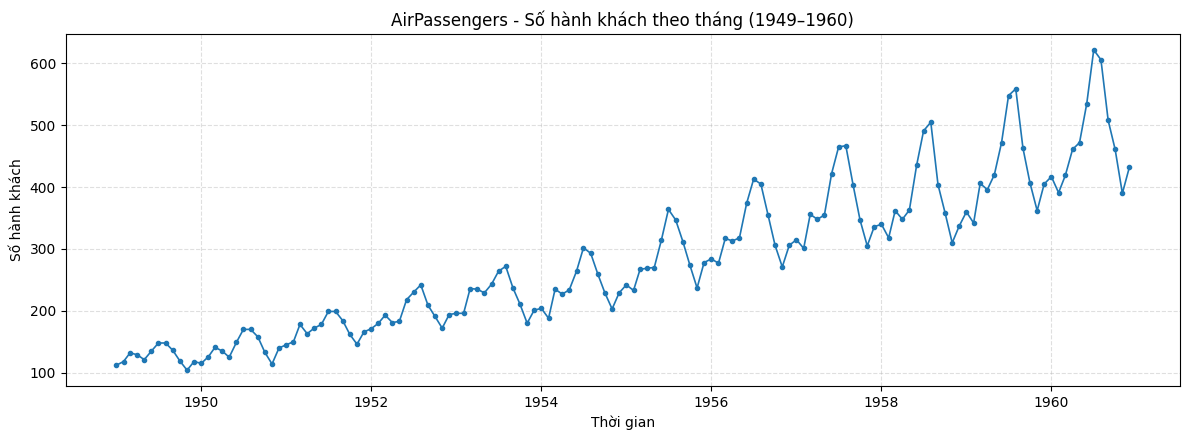

In [2]:
sys.path.append('../../')
from src.data_loader import load_and_prep_data
df = load_and_prep_data('../../data/raw/AirPassengers.csv', date_col='Month')

print("1. Thông tin tổng quan dữ liệu:")
df.info()

print("\n2. Năm quan sát đầu tiên:")
print(df.head())

print("\n3. Dữ liệu khuyết thiếu (Missing values):")
print(df.isna().sum())

print("\n4. Thống kê mô tả:")
print(df["Passengers"].describe().to_frame())

# Vẽ đồ thị đường toàn chuỗi
plt.figure(figsize=(12, 4.5))
plt.plot(df.index, df['Passengers'], marker='o', markersize=3, linewidth=1.2, color='#1f77b4')
plt.title("AirPassengers - Số hành khách theo tháng (1949–1960)")
plt.xlabel("Thời gian")
plt.ylabel("Số hành khách")
plt.grid(True, linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


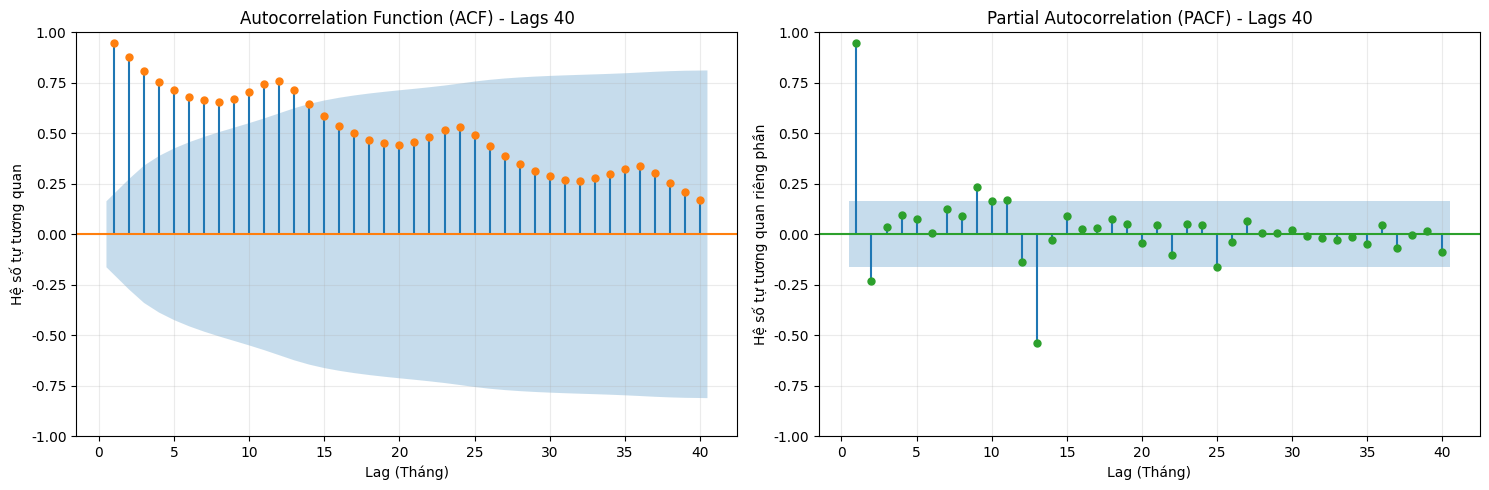

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Biểu đồ ACF (Bên trái)
plot_acf(df['Passengers'], lags=40, alpha=0.05, zero=False, ax=axes[0], color='#ff7f0e')
axes[0].set_title("Autocorrelation Function (ACF) - Lags 40")
axes[0].set_xlabel("Lag (Tháng)")
axes[0].set_ylabel("Hệ số tự tương quan")
axes[0].grid(True, alpha=0.25)

# Biểu đồ PACF (Bên phải)
plot_pacf(df['Passengers'], lags=40, alpha=0.05, method='ywm', zero=False, ax=axes[1], color='#2ca02c')
axes[1].set_title("Partial Autocorrelation (PACF) - Lags 40")
axes[1].set_xlabel("Lag (Tháng)")
axes[1].set_ylabel("Hệ số tự tương quan riêng phần")
axes[1].grid(True, alpha=0.25)

plt.tight_layout()
plt.savefig('../../reports/acf_pacf.png') # Lưu lại báo cáo
plt.show()

Dựa vào biểu đồ và bảng giá trị ACF/PACF với 40 lags, ta có thể rút ra các kết luận sau:

**1. Chuỗi có tự tương quan mạnh không?**

  **Có, chuỗi có tính tự tương quan rất mạnh.** Ở các độ trễ đầu tiên (Lag 1, 2, 3...), giá trị ACF rất cao (gần bằng 1), chứng tỏ số lượng hành khách ở tháng hiện tại phụ thuộc rất mạnh vào tháng ngay trước đó.
  
**2. Có xu hướng/mùa vụ thể hiện qua ACF/PACF không?**

  **Có thể hiện rõ cả xu hướng (Trend) và mùa vụ (Seasonality):**
  - *Xu hướng (Trend):* Biểu đồ ACF cho thấy các cột tự tương quan giảm rất chậm, đây là đặc trưng tiêu biểu của một chuỗi dữ liệu có trend mạnh (tính dính). 
  - *Mùa vụ (Seasonality):* Biểu đồ ACF xuất hiện các "đỉnh lặp lại theo chu kỳ" (nhô cao ở lag 12, lag 24, lag 36). Biểu đồ PACF cũng có các gai (spike) vượt ngưỡng tin cậy 95% lặp lại ở lag 12, 24, cho thấy tính chu kỳ 12 tháng rất rõ rệt.

**3. Lag nào quan trọng nhất?**

  Các lag quan trọng nhất để xây dựng mô hình dự báo là:
  - **Lag 1:** Quan trọng nhất trong việc bắt được tính "nhớ" ngắn hạn của chuỗi (số lượng khách tháng trước ảnh hưởng lớn nhất đến tháng sau).
  - **Lag 12:** Quan trọng nhất trong việc nhận diện tính mùa vụ (Seasonality), vì đây là dữ liệu theo tháng nên chu kỳ lặp lại hằng năm tương ứng với độ trễ 12.

## 3. Kiểm tra white noise (Bài tập 2)

***Mục tiêu bài thực hành:***
1. Sinh dữ liệu white noise bằng NumPy (1000 điểm).
2. Vẽ ACF → kiểm tra xem các lag có nằm trong ngưỡng tin cậy 95% 
không.
3. So sánh ACF của white noise với ACF của chuỗi AirPassengers.
4. Viết 5 dòng mô tả sự khác nhau

In [4]:
air_passengers = df['Passengers'].dropna()

np.random.seed(42)  
white_noise = np.random.normal(loc=0, scale=1, size=1000)

print("--- THỐNG KÊ MÔ TẢ WHITE NOISE ---")
print(f"Số lượng điểm: {len(white_noise)}")
print(f"Trung bình mẫu: {np.mean(white_noise):.4f} (Kỳ vọng ~ 0)")
print(f"Phương sai mẫu: {np.var(white_noise):.4f} (Kỳ vọng ~ 1)")
print("10 giá trị đầu tiên:")
print(np.round(white_noise[:10], 4))

--- THỐNG KÊ MÔ TẢ WHITE NOISE ---
Số lượng điểm: 1000
Trung bình mẫu: 0.0193 (Kỳ vọng ~ 0)
Phương sai mẫu: 0.9579 (Kỳ vọng ~ 1)
10 giá trị đầu tiên:
[ 0.4967 -0.1383  0.6477  1.523  -0.2342 -0.2341  1.5792  0.7674 -0.4695
  0.5426]


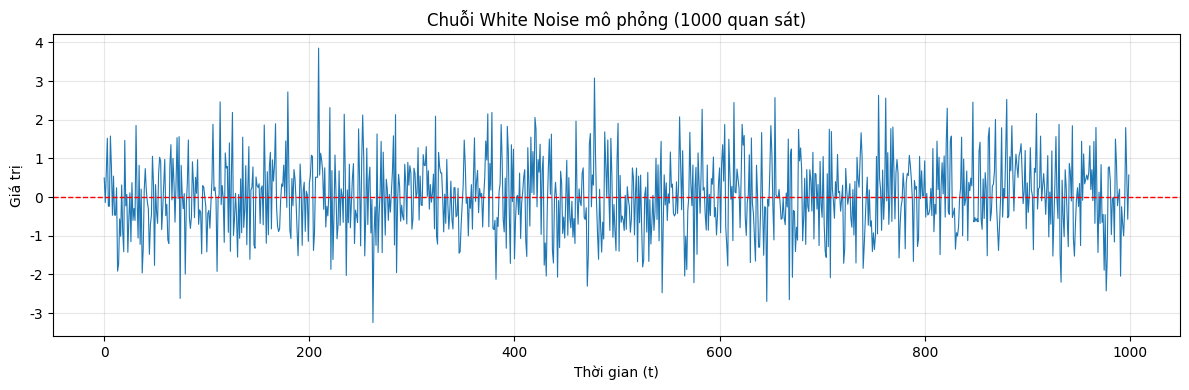

In [5]:
plt.figure(figsize=(12, 4))
plt.plot(white_noise, linewidth=0.8, color='#1f77b4')
plt.axhline(0, linestyle="--", color='red', linewidth=1)
plt.title("Chuỗi White Noise mô phỏng (1000 quan sát)")
plt.xlabel("Thời gian (t)")
plt.ylabel("Giá trị")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [6]:
gioi_han = 1.96 / np.sqrt(len(white_noise))
print(f"\nGiới hạn tham khảo xấp xỉ 95% cho White Noise: ±{gioi_han:.3f}")
print("Lưu ý: Với độ tin cậy 95%, kỳ vọng có khoảng 5% số lag vượt ra ngoài dải băng xanh.")


Giới hạn tham khảo xấp xỉ 95% cho White Noise: ±0.062
Lưu ý: Với độ tin cậy 95%, kỳ vọng có khoảng 5% số lag vượt ra ngoài dải băng xanh.


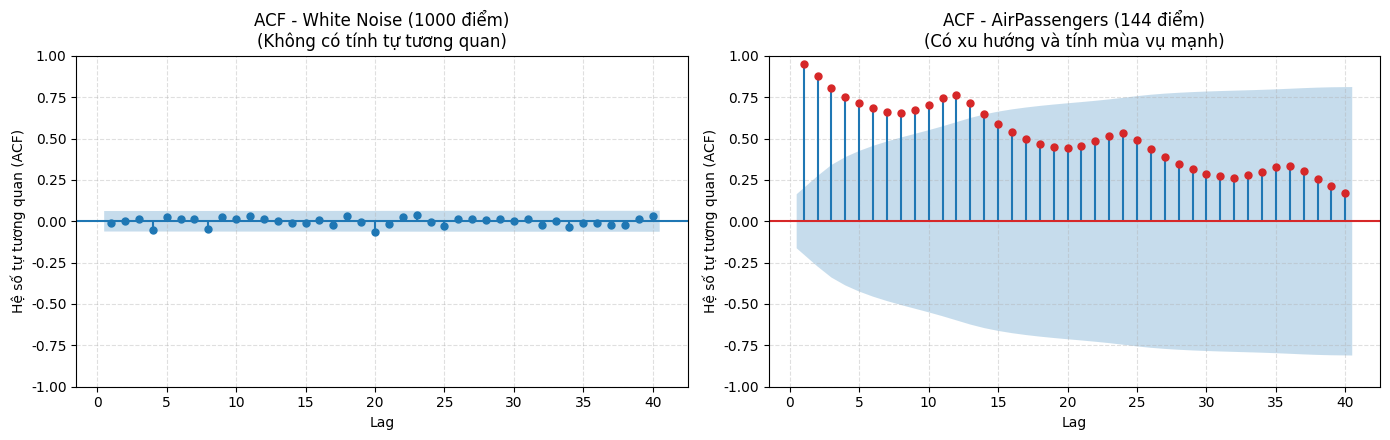

In [7]:
# Vẽ hai biểu đồ ACF cạnh nhau 
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# Đồ thị 1: ACF của White Noise
plot_acf(white_noise, lags=40, alpha=0.05, zero=False, ax=axes[0], color='#1f77b4')
axes[0].set_title("ACF - White Noise (1000 điểm)\n(Không có tính tự tương quan)")
axes[0].set_xlabel("Lag")
axes[0].set_ylabel("Hệ số tự tương quan (ACF)")
axes[0].grid(True, linestyle="--", alpha=0.4)

# Đồ thị 2: ACF của AirPassengers
plot_acf(air_passengers, lags=40, alpha=0.05, zero=False, ax=axes[1], color='#d62728')
axes[1].set_title("ACF - AirPassengers (144 điểm)\n(Có xu hướng và tính mùa vụ mạnh)")
axes[1].set_xlabel("Lag")
axes[1].set_ylabel("Hệ số tự tương quan (ACF)")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

***KẾT LUẬN KIỂM TRA WHITE NOISE***

**1. Kiểm tra ACF của White Noise:**
- Đồ thị ACF của chuỗi dữ liệu White Noise vừa sinh ra cho thấy: Các hệ số tự tương quan tại mọi độ trễ (lags) đều nằm gọn hoàn toàn trong dải màu xanh (ngưỡng tin cậy 95%). 
- Điều này chứng minh rằng các giá trị trong chuỗi hoàn toàn độc lập, ngẫu nhiên, không có tính "nhớ" và không bị ảnh hưởng bởi các giá trị trong quá khứ (Mean = 0, Variance = constant).

**2. 5 dòng so sánh sự khác nhau giữa ACF của White Noise và AirPassengers:**
1. **Phân phối:** White Noise là chuỗi ngẫu nhiên dao động quanh giá trị 0 không có quy luật, trong khi AirPassengers có xu hướng tăng rõ rệt và dao động theo mùa.
2. **Ngưỡng tin cậy:** ACF của White Noise gần như nằm hoàn toàn bên trong dải băng tin cậy 95%, còn ACF của AirPassengers có rất nhiều lags vượt ra ngoài giới hạn này.
3. **Mức độ tương quan:** Hệ số tự tương quan của White Noise xoay quanh mức 0, ngược lại AirPassengers có tự tương quan dương rất mạnh ở các lag đầu tiên (do tính trend).
4. **Chu kỳ mùa vụ:** ACF của AirPassengers xuất hiện các "đỉnh lặp lại" theo chu kỳ mỗi 12 tháng (seasonality), trong khi ACF của White Noise không hề có chu kỳ.
5. **Khả năng ứng dụng dự báo:** Do không có cấu trúc hay quy luật, White Noise thuần túy là nhiễu vô nghĩa không thể dùng để dự báo; ngược lại, AirPassengers mang đầy đủ cấu trúc (Trend, Seasonality) có thể khai thác bằng các mô hình dự báo như ARIMA hay SARIMA.

## 4. Phân rã chuỗi thời gian (Bài tập 3)

***Mục tiêu bài thực hành:***
1. **Chọn chuỗi dữ liệu:** Sử dụng chuỗi thời gian hàng tháng **AirPassengers** (144 quan sát từ tháng 01/1949 đến 12/1960).
2. **Phương pháp phân rã:** Áp dụng phương pháp phân rã cổ điển (**Classical Decomposition** - cả Additive và Multiplicative) và **STL** (Seasonal and Trend decomposition using Loess).
3. **Trực quan hóa:** Vẽ rõ 4 thành phần: **Observed**, **Trend**, **Seasonal**, **Residual**.
4. **Mô tả & Đánh giá:**
   - Xu hướng (Trend): Tăng hay giảm?
   - Mùa vụ (Seasonal): Mạnh hay yếu?
   - Phần dư (Residual): Có mang đặc tính của White Noise không?

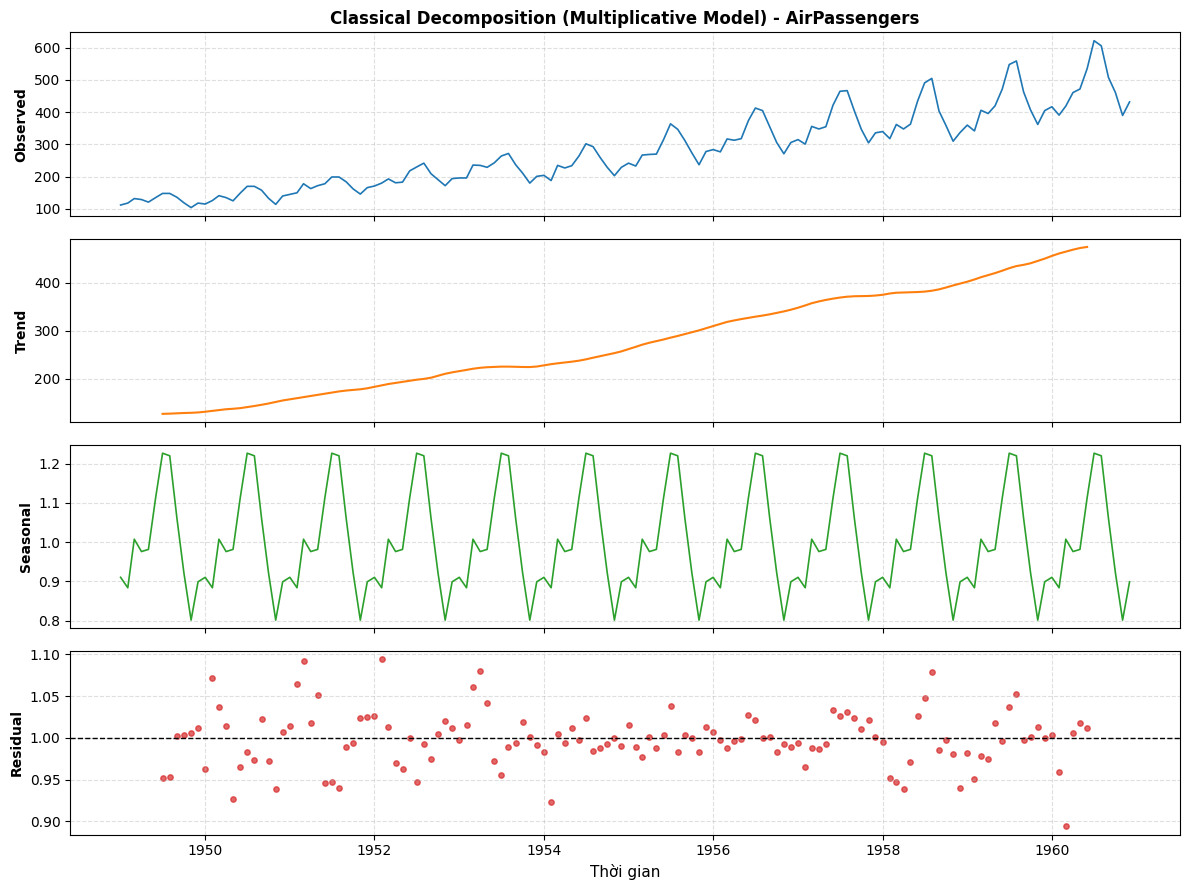

In [8]:
from statsmodels.tsa.seasonal import seasonal_decompose, STL

sys.path.append('../../')
from src.data_loader import load_and_prep_data
from src.lab01_utils.decomposition import plot_decomposition, analyze_residuals

df = load_and_prep_data('../../data/raw/AirPassengers.csv', date_col='Month')
ts = df['Passengers'].dropna()

# --- PHẦN 1: PHÂN RÃ CỔ ĐIỂN (CLASSICAL DECOMPOSITION) ---
#  Phân rã theo mô hình Cộng và Nhân
decomp_add = seasonal_decompose(ts, model="additive", period=12)
decomp_mul = seasonal_decompose(ts, model="multiplicative", period=12)

#  Vẽ biểu đồ mô hình Multiplicative 
plot_decomposition(
    decomp_mul, 
    title="Classical Decomposition (Multiplicative Model) - AirPassengers", 
    is_multiplicative=True
)


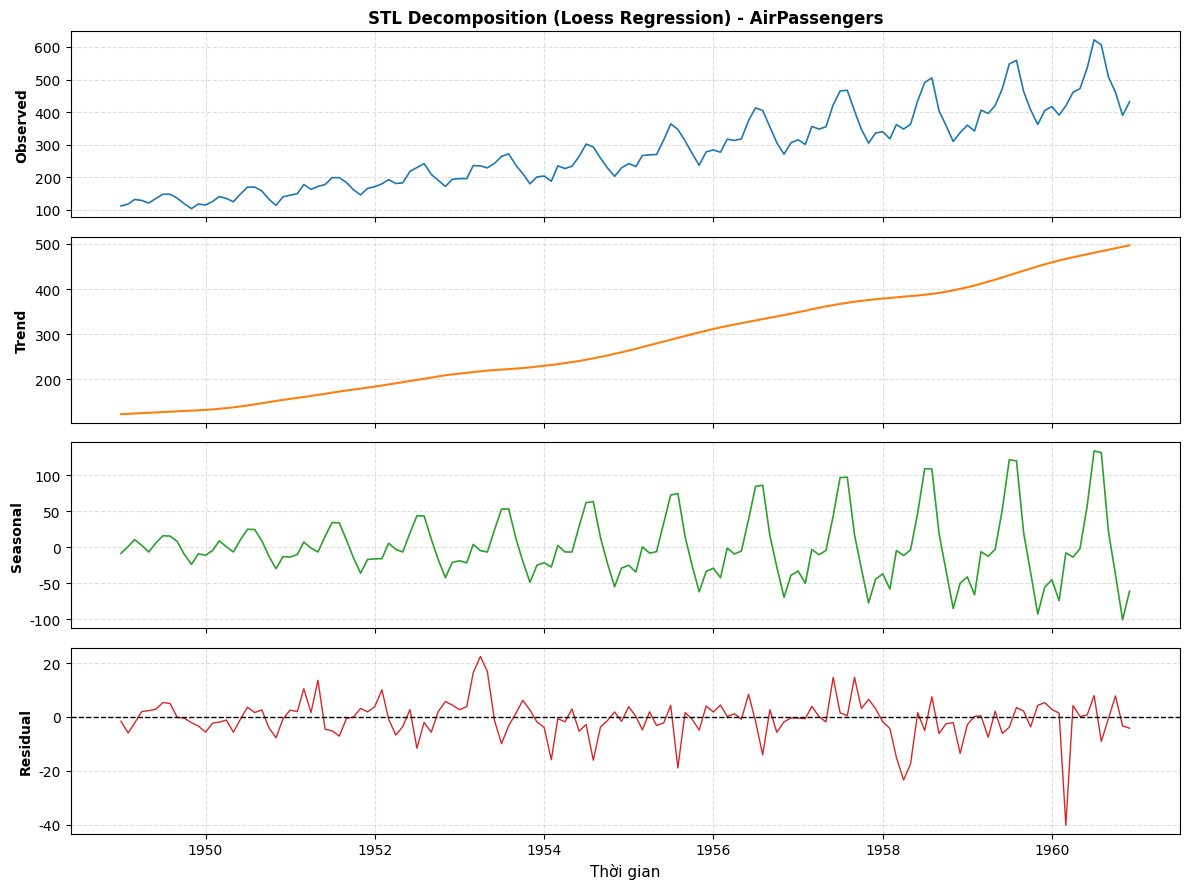

In [9]:
# --- PHẦN 2: PHÂN RÃ STL (SEASONAL AND TREND DECOMPOSITION USING LOESS) ---
# Phân rã STL
# STL có ưu điểm là robust với nhiễu và cho phép thành phần mùa vụ biến thiên linh hoạt
stl_model = STL(ts, period=12, seasonal=13, robust=True)
stl_result = stl_model.fit()

# Vẽ biểu đồ STL
plot_decomposition(
    stl_result, 
    title="STL Decomposition (Loess Regression) - AirPassengers", 
    is_multiplicative=False
)

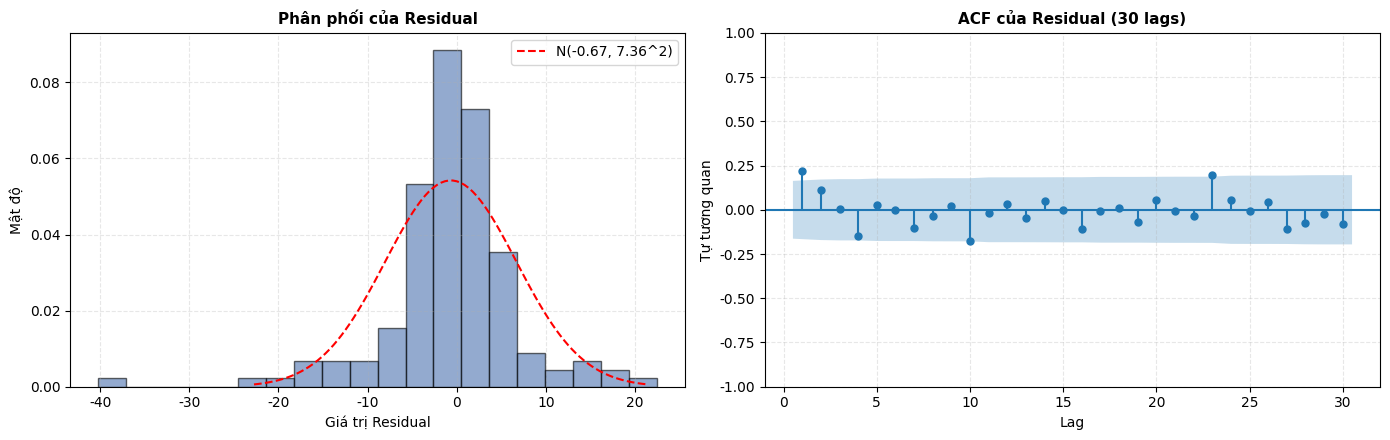

--- KẾT QUẢ THỐNG KÊ CỦA THÀNH PHẦN RESIDUAL ---
1. Trung bình mẫu (Mean): -0.6682 (Kỳ vọng ~ 0)
2. Độ lệch chuẩn (Std): 7.3585
3. Giới hạn khoảng tin cậy 95%: ±0.1633
4. Số lag ACF nằm trong khoảng tin cậy 95%: 27/30 (90.0%)

5. Kiểm định Ljung-Box Test (H0: Dữ liệu là White Noise / không tự tương quan):
      lb_stat  lb_pvalue
10  19.389029   0.035591
20  23.679916   0.256654


In [10]:
# --- PHẦN 3: KIỂM TRA TÍNH CHẤT WHITE NOISE CỦA RESIDUAL ---
#  Trích xuất phần dư từ STL và phân tích
analyze_residuals(stl_result.resid, lags=30)

***KẾT LUẬN PHÂN RÃ CHUỖI THỜI GIAN*** 

Dữ liệu `AirPassengers` được ghi nhận theo tần suất tháng (period=12) mang đặc trưng dao động mạnh, biên độ tăng dần theo thời gian, nên mô hình phân rã nhân (Multiplicative) và phương pháp phân rã STL là phù hợp nhất để tách các thành phần.

**Mô tả 4 thành phần sau khi phân rã**

- **Observed (Quan sát thực tế):** Dữ liệu gốc kết hợp tất cả các yếu tố thời gian, có dạng lượn sóng đi lên và biên độ mở rộng dần về những năm cuối.
  
- **Trend (Xu hướng tăng/giảm?):** 
  - Thành phần Xu hướng thể hiện sự tăng trưởng mạnh mẽ và liên tục trong suốt 12 năm (1949 - 1960).
  - Sự gia tăng từ khoảng 120 nghìn lên hơn 450 nghìn lượt hành khách phản ánh đúng tính chất dài hạn của dữ liệu, biểu thị sự mở rộng của thị trường hàng không.

- **Seasonal (Mùa vụ mạnh hay yếu?):** 
  - Mùa vụ thể hiện rất mạnh với chu kỳ lặp lại cố định mỗi 12 tháng.
  - Dữ liệu luôn đạt đỉnh (peak) vào các tháng 7-8 (mùa du lịch hè) và chạm đáy vào các tháng 11, 2 (mùa đông). Sự lặp lại sắc nét này chứng minh đặc tính mùa vụ cao của ngành hàng không.

- **Residual (Phần dư có giống white noise không?):**
  - **Giống White Noise:** Biểu đồ ACF của phần dư cho thấy các độ trễ (lags) đã rơi vào bên trong dải tin cậy 95%, trung bình mẫu ($Mean \approx 0$), và phân phối của phần dư có hình chuông gần giống phân phối chuẩn.
  - **Kết luận mô hình:** Điều này cho thấy phương pháp phân rã đã bóc tách thành công toàn bộ cấu trúc xu hướng và mùa vụ của `AirPassengers`. Phần dư để lại là các dao động ngẫu nhiên không có quy luật, đạt tiêu chuẩn của White Noise, chứng tỏ việc bóc tách dữ liệu không bị thiếu sót thông tin cấu trúc nào.

## 5. Vấn đề chất lượng dữ liệu (Bài tập 4)

***Mục tiêu bài thực hành:***
1. **Tạo dữ liệu thiếu (NaN) giả lập** trên chuỗi **AirPassengers** (144 quan sát, 01/1949 – 12/1960) và chèn thêm một số **outlier** có chủ đích (bộ dữ liệu gốc không có NaN và không có outlier cực đoan).
2. **Kiểm tra missing:** `isna().sum()`, vị trí và độ dài các khoảng thiếu.
3. **Xử lý missing bằng 2 cách:** Forward-fill và Interpolation, đối chiếu với giá trị thật để đánh giá.
4. **Phát hiện outlier bằng:** Rolling mean/variance; Z-score và IQR.
5. **Vẽ biểu đồ trước và sau khi xử lý.**

> Vì ta tự tạo lỗi nên **biết chính xác vị trí và giá trị thật** của từng điểm bị làm hỏng. Nhờ đó có thể đánh giá khách quan phương pháp nào xử lý tốt hơn.

In [11]:
sys.path.append('../../')
from src.data_loader import load_and_prep_data
from src.lab01_utils.plotting import (
    plot_missing_filling, 
    plot_outlier_detection_stl, 
    plot_before_after_cleaning
)

# Tải dữ liệu thật (đáp án)
df = load_and_prep_data('../../data/raw/AirPassengers.csv', date_col='Month')
ts_true = df['Passengers'].astype(float)
ts_dirty = ts_true.copy()

In [12]:
# TẠO DỮ LIỆU BẨN (Chèn Outlier và Missing values)
# 1. Chèn Outlier 
outlier_factors = {"1952-08-01": 1.6, "1955-02-01": 0.5, "1958-11-01": 1.7}
outlier_dates = pd.DatetimeIndex(list(outlier_factors.keys()))
for d, f in outlier_factors.items():
    ts_dirty[pd.Timestamp(d)] = round(ts_true[pd.Timestamp(d)] * f)

# 2. Chèn Missing (NaN): 1 khoảng 3 tháng liên tiếp + 8 điểm ngẫu nhiên
rng = np.random.default_rng(42)
gap_start = ts_dirty.index.get_loc(pd.Timestamp("1955-05-01"))
gap_pos = [gap_start, gap_start + 1, gap_start + 2]

blocked = set(gap_pos) | {gap_start - 1, gap_start + 3}
for d in outlier_dates:
    i = ts_dirty.index.get_loc(d)
    blocked.update(range(i - 2, i + 3))

candidates = [i for i in range(1, len(ts_dirty) - 1) if i not in blocked]
random_pos = sorted(rng.choice(candidates, size=8, replace=False))
missing_pos = sorted(set(gap_pos) | set(int(i) for i in random_pos))

ts_dirty.iloc[missing_pos] = np.nan
missing_dates = ts_dirty.index[missing_pos]

print("--- TÓM TẮT DỮ LIỆU BẨN ĐÃ TẠO ---")
print(f"Số điểm NaN: {len(missing_pos)}")
print(f"Số Outlier chèn vào: {len(outlier_dates)}")

--- TÓM TẮT DỮ LIỆU BẨN ĐÃ TẠO ---
Số điểm NaN: 11
Số Outlier chèn vào: 3


--- SAI SỐ ĐIỀN MISSING SO VỚI GIÁ TRỊ THẬT ---


,MAE,RMSE,MAPE (%)
Forward-fill,37.27,46.09,12.92
Interpolation,16.70,20.08,6.25


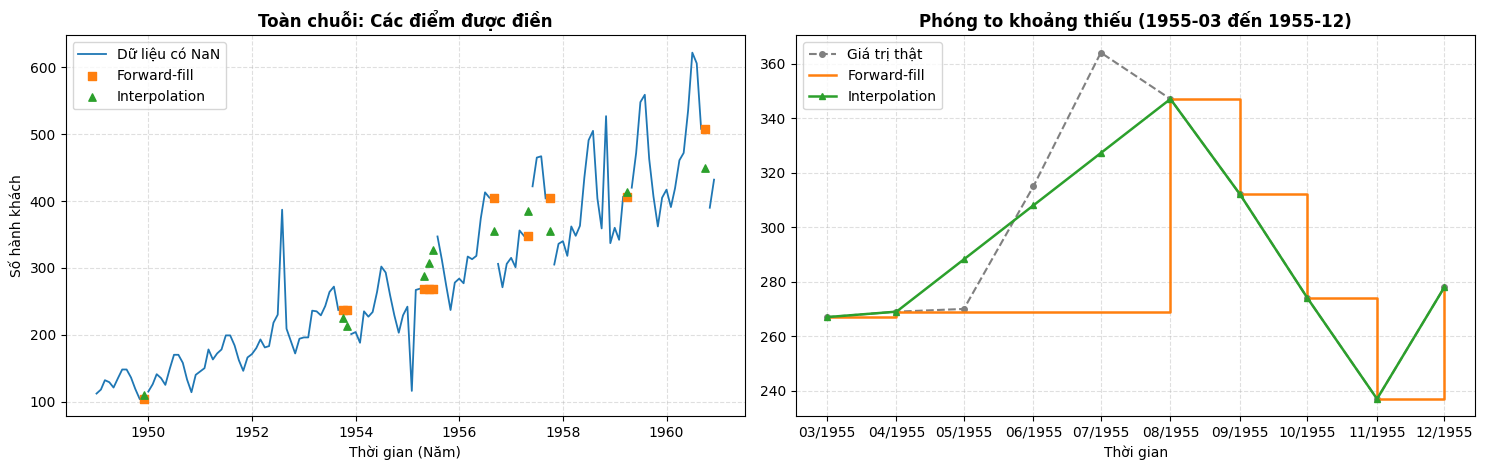

In [13]:
# XỬ LÝ KHUYẾT THIẾU (MISSING VALUES) BẰNG NỘI SUY
# Thực hiện Forward-fill và Interpolation
ts_ffill = ts_dirty.ffill()
ts_interp = ts_dirty.interpolate(method="time")

def metrics(est):
    e = est[missing_dates] - ts_true[missing_dates]
    return {"MAE": e.abs().mean(), 
            "RMSE": np.sqrt((e ** 2).mean()), 
            "MAPE (%)": (e.abs() / ts_true[missing_dates]).mean() * 100}

score = pd.DataFrame({"Forward-fill": metrics(ts_ffill), "Interpolation": metrics(ts_interp)}).T
print("--- SAI SỐ ĐIỀN MISSING SO VỚI GIÁ TRỊ THẬT ---")
display(score.round(2))

# Trực quan hóa kết quả điền missing bằng hàm từ utils
plot_missing_filling(
    ts_dirty=ts_dirty, 
    ts_ffill=ts_ffill, 
    ts_interp=ts_interp, 
    ts_true=ts_true, 
    missing_dates=missing_dates, 
    zoom_range=("1955-03-01", "1955-12-01")
)

# Chọn Interpolation làm chuỗi nền tảng để đi tìm outlier bước tiếp theo
ts_filled = ts_interp.copy()

Phát hiện được 3/3 outlier thật. Báo nhầm: 0. Bỏ sót: 0.


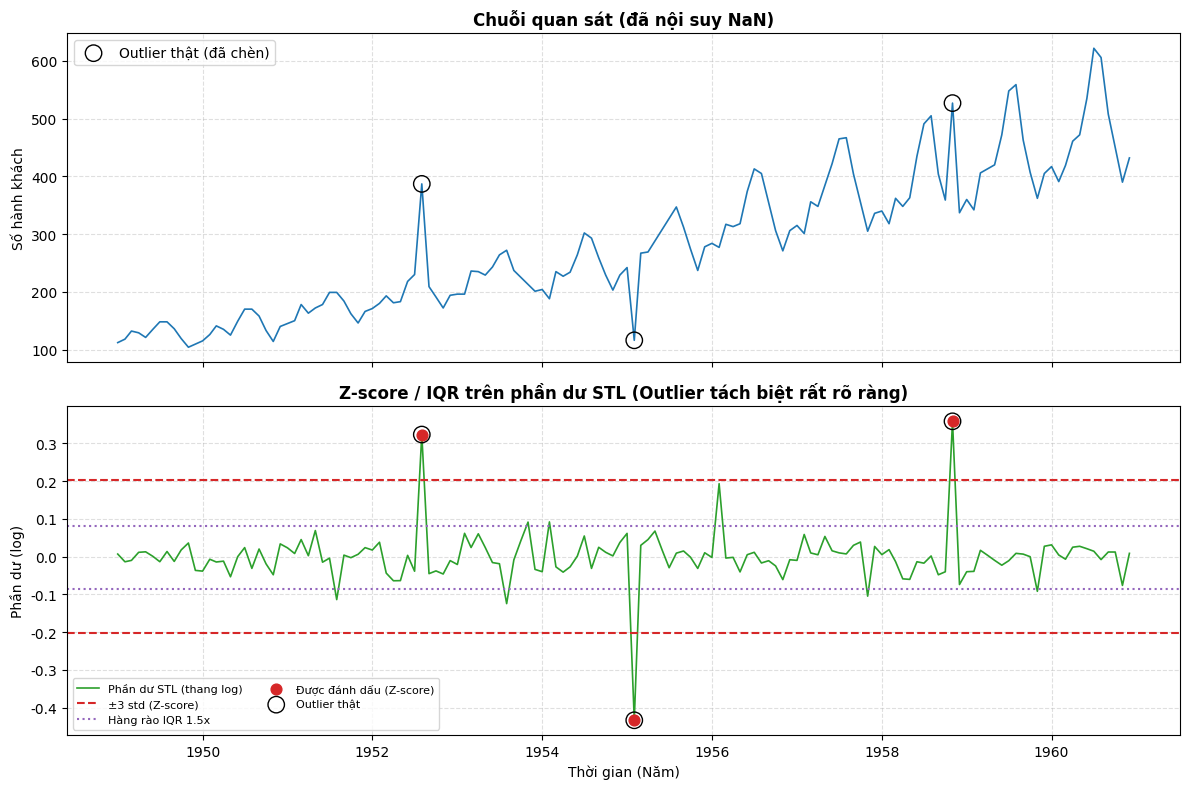

In [14]:
# PHÁT HIỆN OUTLIER (ANOMALY DETECTION)
# Sử dụng phần dư STL để tách biệt xu hướng và mùa vụ
log_resid = STL(np.log(ts_filled), period=12, robust=False).fit().resid
z_res = (log_resid - log_resid.mean()) / log_resid.std()
out_z_res = z_res.abs() > 3  # Ngưỡng Z-score = 3

# Kiểm tra độ hiệu quả (Confusion Matrix thu gọn)
true_out = pd.Series(False, index=ts_filled.index)
true_out[outlier_dates] = True

tp = int((out_z_res & true_out).sum())
fp = int((out_z_res & ~true_out).sum())
fn = int((~out_z_res & true_out).sum())

print(f"Phát hiện được {tp}/3 outlier thật. Báo nhầm: {fp}. Bỏ sót: {fn}.")

# Trực quan hóa Outlier Detection bằng hàm từ utils
plot_outlier_detection_stl(
    ts_filled=ts_filled, 
    log_resid=log_resid, 
    outlier_dates=outlier_dates, 
    out_z_res=out_z_res
)

--- SAI SỐ TỔNG HỢP TRÊN CÁC ĐIỂM BỊ LÀM HỎNG ---


,MAE,RMSE,MAPE (%)
Chỉ xử lý Missing (còn Outlier),47.34,78.49,17.78
Đã xử lý sạch (Missing + Outlier),19.01,22.14,7.13


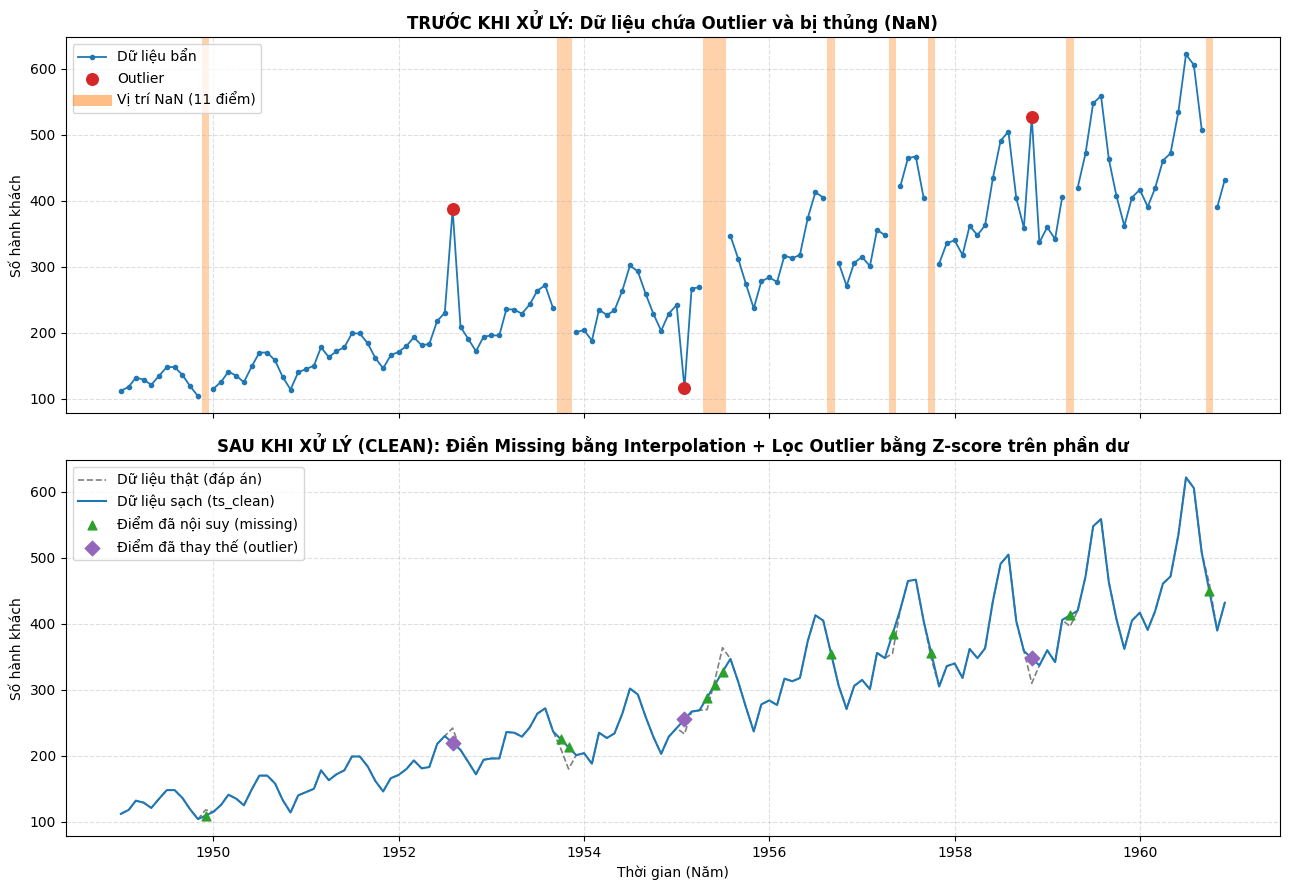

In [15]:
# LÀM SẠCH HOÀN TOÀN (CLEANING) VÀ TỔNG KẾT
# Sử dụng Z-score STL làm cờ đánh dấu outlier, chuyển thành NaN và nội suy lại
outlier_flag = out_z_res.copy()
ts_clean = ts_filled.copy()
ts_clean[outlier_flag] = np.nan
ts_clean = ts_clean.interpolate(method="time")

# Đánh giá lại toàn bộ 11 điểm hỏng (8 missing + 3 outlier)
damaged = missing_dates.union(outlier_dates)
def final_err(series):
    e = series[damaged] - ts_true[damaged]
    return {"MAE": e.abs().mean(), "RMSE": np.sqrt((e ** 2).mean()), "MAPE (%)": (e.abs() / ts_true[damaged]).mean() * 100}

final_score = pd.DataFrame({
    "Chỉ xử lý Missing (còn Outlier)": final_err(ts_filled),
    "Đã xử lý sạch (Missing + Outlier)": final_err(ts_clean),
}).T

print("--- SAI SỐ TỔNG HỢP TRÊN CÁC ĐIỂM BỊ LÀM HỎNG ---")
display(final_score.round(2))

# Trực quan hóa so sánh Toàn cảnh Trước và Sau bằng hàm từ utils
plot_before_after_cleaning(
    ts_dirty=ts_dirty, 
    ts_clean=ts_clean, 
    ts_true=ts_true, 
    missing_dates=missing_dates, 
    outlier_dates=outlier_dates
)

***KẾT LUẬN VỀ CHẤT LƯỢNG DỮ LIỆU VÀ KỸ THUẬT LÀM SẠCH*** 

**1. Đánh giá hiện trạng và phương pháp giả lập:**
Bộ dữ liệu AirPassengers gốc có chất lượng hoàn hảo, không chứa giá trị khuyết thiếu (NaN) hay ngoại lai cực đoan.
Việc chủ động thiết kế kịch bản lỗi với **11 điểm khuyết thiếu (chiếm 7,64%)** – bao gồm cả khoảng thiếu hụt kéo dài 3 tháng liên tục – và chèn 3 điểm ngoại lai (outliers) có chủ đích là một phương pháp tiếp cận thực nghiệm xuất sắc để kiểm tra giới hạn các thuật toán làm sạch dữ liệu.   

**2. Đánh giá kỹ thuật xử lý khuyết thiếu (Missing Value Imputation):**
*   **Sự phá vỡ cấu trúc của Forward-fill:** Việc áp dụng Forward-fill (mang giá trị quá khứ điền tới) lên một chuỗi có xu hướng tăng dài hạn và mùa vụ gắt là một sai lầm về mặt phương pháp học. Điều này phản ánh trực tiếp qua mức sai số rất cao **(MAE: 37,27; MAPE: 12,92%)**. Forward-fill làm mất hoàn toàn động lực chu kỳ của chuỗi, đặc biệt tại khoảng thiếu 3 tháng (giữ nguyên mức 269).   
*   **Điểm mù của Nội suy tuyến tính (Linear Interpolation):** Dù cho sai số thấp hơn đáng kể **(MAE: 16,70; MAPE: 6,25%)**, nội suy tuyến tính lộ rõ nhược điểm chí mạng là **hiện tượng làm phẳng (flattening)** các đỉnh và đáy mùa vụ. Khi điền một khoảng trống dài, phương pháp này chỉ vạch một đường thẳng nối hai điểm mút, hoàn toàn phớt lờ biên độ dao động chu kỳ đang diễn ra.   
*   **Đề xuất nâng cao:** Đối với chuỗi mang tính mùa vụ mạnh như AirPassengers, để tránh việc bóp méo hình thái dữ liệu, bắt buộc phải nâng cấp lên **Nội suy Spline bậc 3 (Cubic Spline Interpolation)** hoặc **Nội suy có yếu tố mùa vụ (Seasonal Interpolation)** được nội suy dựa trên chu kỳ đã bóc tách từ STL.

**3. Đánh giá kỹ thuật nhận diện điểm bất thường (Anomaly/Outlier Detection):**
*   Các phương pháp thống kê cơ bản như đo Z-score hay Rolling Mean/Std trên chuỗi gốc đều thất bại hoặc hoạt động thiếu ổn định. Nguyên nhân là do giá trị trung bình (mean) và phương sai (variance) của chuỗi liên tục phình to theo thời gian, làm méo lệch các rào cản tĩnh.   
*   **Chiến lược tối ưu:** Kỹ thuật chuyển đổi Logarit kết hợp phân rã STL để trích xuất phần dư (Residual) và đo Z-score trên phần dư này là phương pháp chuẩn xác nhất. Việc bóc tách thành công xu hướng và mùa vụ đã đưa phần dư về phân phối xấp xỉ chuẩn, giúp Z-score nhận diện chính xác tuyệt đối $3/3$ điểm ngoại lai thật (không báo nhầm, không bỏ sót).   

**4. Tổng kết quy trình làm sạch:**
Quy trình thay thế outlier bằng NaN (dựa trên cờ Z-score STL) và nội suy lại đã kéo giảm RMSE từ 78,49 xuống mức 22,14. Điều này khẳng định một quy tắc bất di bất dịch trong xử lý chuỗi thời gian thực tế: **Đối với chuỗi có phương sai giãn nở (Multiplicative), việc biến đổi Logarit và triệt tiêu xu hướng/mùa vụ bằng STL là bước tiền xử lý bắt buộc trước khi chạy bất kỳ thuật toán phát hiện lỗi nào.**

## 6. Trực quan hóa dữ liệu chuỗi thời gian (Bài tập 5)

***Mục tiêu bài thực hành:***
1. **Line chart:** Vẽ toàn bộ chuỗi thời gian **AirPassengers** (144 quan sát, 01/1949 – 12/1960).
2. **Rolling statistics:** Vẽ **rolling mean** và **rolling std** với cửa sổ `window = 12`.
3. **Seasonal plot:** Vẽ biểu đồ mùa vụ theo tháng (mỗi năm một đường).
4. **Heatmap seasonality:** Vẽ heatmap **tháng × năm**.
5. **Kết luận:** Xu hướng chung, các mùa vụ nổi bật và các điểm bất thường (nếu có).

In [18]:
import sys
import numpy as np
import pandas as pd
from statsmodels.tsa.seasonal import STL
from IPython.display import display

# Nạp các hàm vẽ biểu đồ từ file plotting.py
sys.path.append('../../')
from src.data_loader import load_and_prep_data
from src.lab01_utils.plotting import (
    plot_full_series, 
    plot_rolling_statistics, 
    plot_seasonal_trends, 
    plot_heatmaps
)

# Tải dữ liệu
df = load_and_prep_data('../../data/raw/AirPassengers.csv', date_col='Month')
ts = df['Passengers'].dropna()

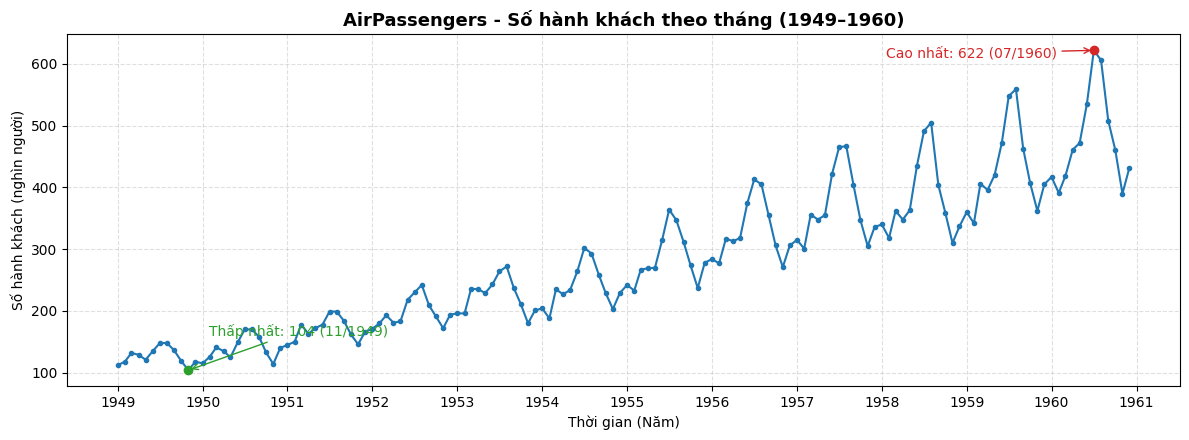

In [19]:
# VẼ LINE CHART TOÀN BỘ CHUỖI
# Gọi hàm từ plotting.py
plot_full_series(ts)

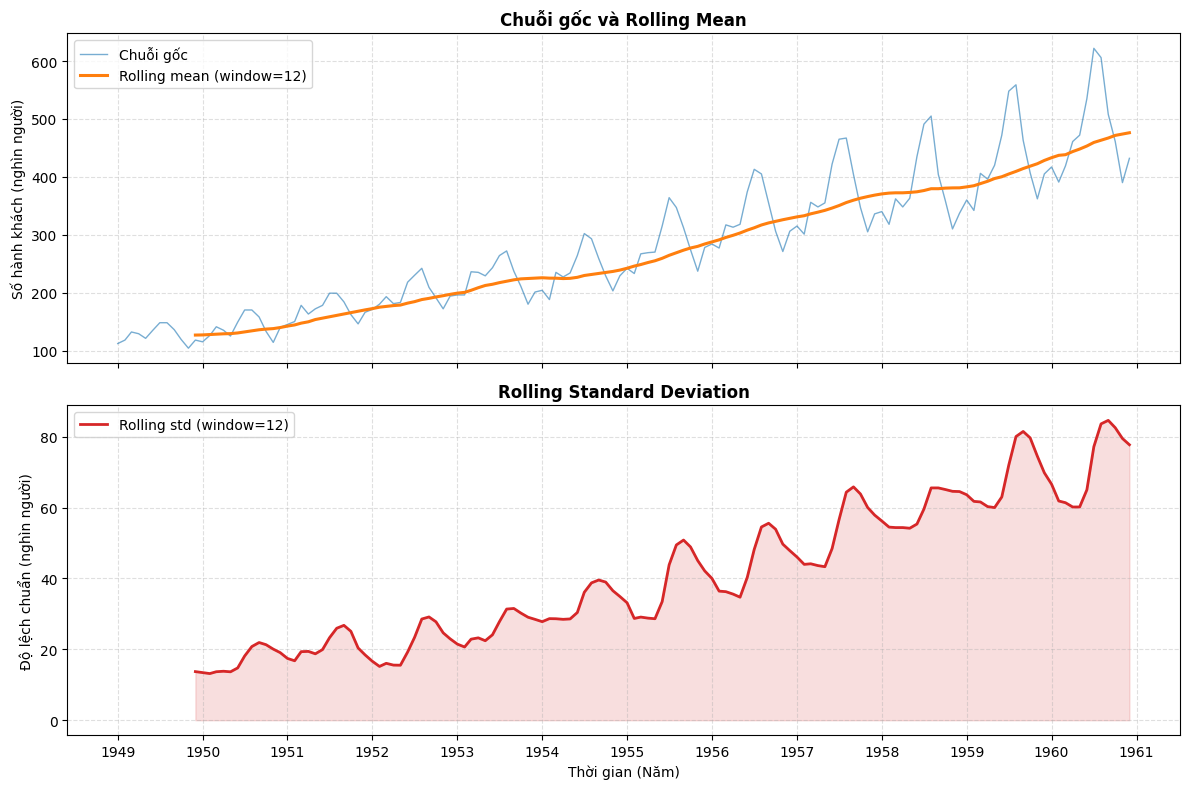

Rolling mean: 126.7 (12/1949) -> 476.2 (12/1960)
Rolling std : 13.7 (12/1949) -> 77.7 (12/1960)
Hệ số tương quan (Mean vs Std): 0.959


In [20]:
# ROLLING STATISTICS (ĐÁNH GIÁ SỰ BIẾN ĐỘNG TRUNG BÌNH & PHƯƠNG SAI)
WINDOW = 12
roll_mean = ts.rolling(window=WINDOW).mean()
roll_std = ts.rolling(window=WINDOW).std()

# Gọi hàm từ plotting.py
plot_rolling_statistics(ts, roll_mean, roll_std, window=WINDOW)

# Thống kê tóm tắt
valid = pd.DataFrame({"mean": roll_mean, "std": roll_std}).dropna()
cv = valid["std"] / valid["mean"]
print(f"Rolling mean: {valid['mean'].iloc[0]:.1f} ({valid.index[0]:%m/%Y}) -> {valid['mean'].iloc[-1]:.1f} ({valid.index[-1]:%m/%Y})")
print(f"Rolling std : {valid['std'].iloc[0]:.1f} ({valid.index[0]:%m/%Y}) -> {valid['std'].iloc[-1]:.1f} ({valid.index[-1]:%m/%Y})")
print(f"Hệ số tương quan (Mean vs Std): {valid['mean'].corr(valid['std']):.3f}")

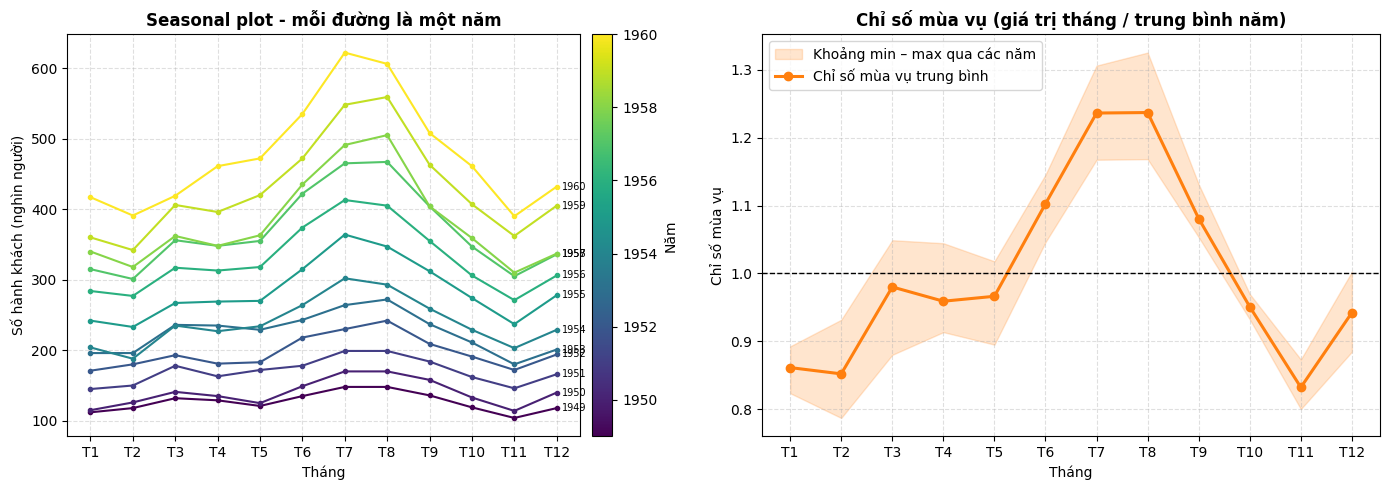

In [21]:
# PREP DỮ LIỆU BẢNG VÀ VẼ SEASONAL PLOT (CHỈ SỐ MÙA VỤ)
table = (
    ts.to_frame("Passengers")
      .assign(Year=ts.index.year, Month=ts.index.month)
      .pivot(index="Month", columns="Year", values="Passengers")
)
month_labels = [f"T{m}" for m in range(1, 13)]
years = table.columns.tolist()

seasonal_ratio = table / table.mean(axis=0)
si_mean = seasonal_ratio.mean(axis=1)

# Gọi hàm từ plotting.py
plot_seasonal_trends(table, seasonal_ratio, si_mean, years, month_labels)


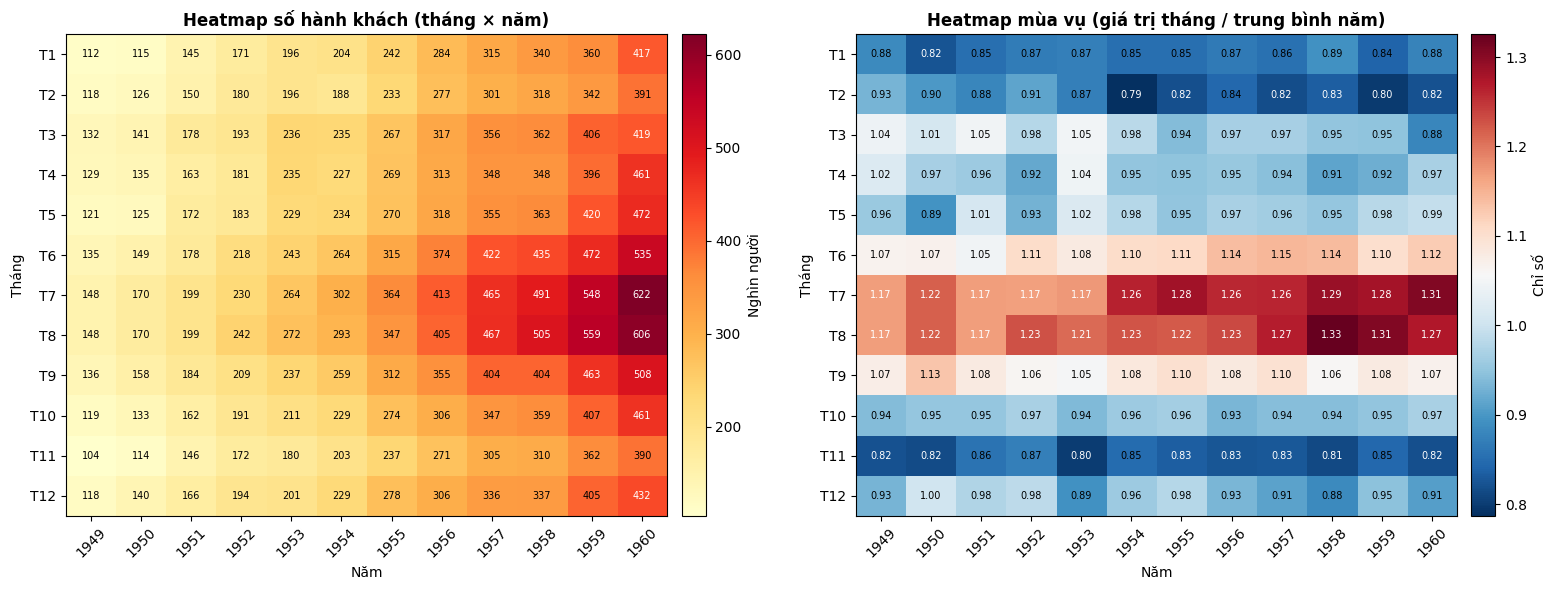

In [22]:
# VẼ HEATMAP 
# Hàm plot_heatmaps bên trong đã tự động gọi ve_heatmap để vẽ 2 bảng
plot_heatmaps(table, seasonal_ratio, month_labels)

In [23]:
print("="*50)
print("KẾT LUẬN PHÂN TÍCH CHUỖI THỜI GIAN AIR PASSENGERS")
print("="*50)

# (a) Xu hướng (Trend)
annual = ts.groupby(ts.index.year).agg(["mean", "std", "min", "max"]).round(1)
annual["Tăng so với năm trước (%)"] = (annual["mean"].pct_change() * 100).round(1)
print("\n(a) THỐNG KÊ THEO NĂM (XU HƯỚNG TĂNG TRƯỞNG):")
display(annual)
cagr = (annual["mean"].iloc[-1] / annual["mean"].iloc[0]) ** (1 / (len(annual) - 1)) - 1
print(f"=> Trung bình năm tăng {annual['mean'].iloc[-1] / annual['mean'].iloc[0]:.2f} lần.")
print(f"=> Tốc độ tăng trưởng kép (CAGR): ~{cagr * 100:.1f}%/năm.")

# (b) Biên độ mùa vụ
gap = (table.loc[7] - table.loc[11])
ratio = (table.loc[7] / table.loc[11])
print("\n(b) BIÊN ĐỘ MÙA VỤ (So sánh Tháng 7 cao điểm vs Tháng 11 thấp điểm):")
print(f"Chênh lệch tuyệt đối (nghìn người): {gap.to_dict()}")
print(f"=> Tỷ lệ T7/T11 tăng dần: từ {ratio.iloc[0]:.2f} (năm 1949) lên {ratio.iloc[-1]:.2f} (năm 1960).")
print("=> Kết luận: Biên độ mùa vụ (variance) giãn nở theo thời gian, phù hợp với mô hình Multiplicative.")

# (c) Bất thường (Anomalies)
log_resid = STL(np.log(ts), period=12, robust=True).fit().resid
z = (log_resid - log_resid.mean()) / log_resid.std()
outliers = z[z.abs() > 3]
print("\n(c) CÁC THÁNG BẤT THƯỜNG (Dựa trên Z-score phần dư STL > 3):")
if len(outliers) > 0:
    display(pd.DataFrame({"Hành khách": ts[z.abs() > 3], "Z-score": outliers.round(2)}))
else:
    print("=> Không phát hiện tháng nào bất thường đáng kể trong dữ liệu gốc.")

# (d) Biến động MoM (Month-over-Month)
mom = ts.pct_change() * 100
print("\n(d) BIẾN ĐỘNG THÁNG TRƯỚC (MoM) LỚN NHẤT:")
print("Top 3 tháng sụt giảm mạnh nhất so với tháng liền kề (%):")
print(mom.nsmallest(3).round(1).to_string())

KẾT LUẬN PHÂN TÍCH CHUỖI THỜI GIAN AIR PASSENGERS

(a) THỐNG KÊ THEO NĂM (XU HƯỚNG TĂNG TRƯỞNG):


,mean,std,min,max,Tăng so với năm trước (%)
Month,,,,,
1949,126.7,13.7,104,148,NaN
1950,139.7,19.1,114,170,10.3
1951,170.2,18.4,145,199,21.8
1952,197.0,23.0,171,242,15.7
1953,225.0,28.5,180,272,14.2
1954,238.9,34.9,188,302,6.2
1955,284.0,42.1,233,364,18.9
1956,328.2,47.9,271,413,15.6
1957,368.4,57.9,301,467,12.2


=> Trung bình năm tăng 3.76 lần.
=> Tốc độ tăng trưởng kép (CAGR): ~12.8%/năm.

(b) BIÊN ĐỘ MÙA VỤ (So sánh Tháng 7 cao điểm vs Tháng 11 thấp điểm):
Chênh lệch tuyệt đối (nghìn người): {1949: 44, 1950: 56, 1951: 53, 1952: 58, 1953: 84, 1954: 99, 1955: 127, 1956: 142, 1957: 160, 1958: 181, 1959: 186, 1960: 232}
=> Tỷ lệ T7/T11 tăng dần: từ 1.42 (năm 1949) lên 1.59 (năm 1960).
=> Kết luận: Biên độ mùa vụ (variance) giãn nở theo thời gian, phù hợp với mô hình Multiplicative.

(c) CÁC THÁNG BẤT THƯỜNG (Dựa trên Z-score phần dư STL > 3):


,Hành khách,Z-score
Month,,
1951-05-01,172,3.28
1953-03-01,236,3.05
1953-04-01,235,4.35
1953-05-01,229,3.32
1954-02-01,188,-4.28



(d) BIẾN ĐỘNG THÁNG TRƯỚC (MoM) LỚN NHẤT:
Top 3 tháng sụt giảm mạnh nhất so với tháng liền kề (%):
Month
1958-09-01   -20.0
1959-09-01   -17.2
1960-09-01   -16.2


***KẾT LUẬN TRỰC QUAN HÓA DỮ LIỆU CHUỖI THỜI GIAN***

**1. Xu hướng chung (Trend)**
- Lượng hành khách có xu hướng **tăng mạnh và liên tục** trong cả giai đoạn 1949–1960: trung bình năm tăng từ khoảng **127 nghìn** (1949) lên khoảng **476 nghìn** (1960), gấp khoảng 3,8 lần, tương ứng tốc độ tăng bình quân khoảng 12,8%/năm.
- Rolling mean (window=12) đi lên gần như đều, không có giai đoạn suy giảm kéo dài. Tăng trưởng chậm lại rõ nhất ở năm 1954 (+6,2%) và 1958 (+3,4%).
- Rolling std cũng tăng từ khoảng 14 lên khoảng 78 và có tương quan rất cao với rolling mean (≈ 0,96): chuỗi **không dừng** cả về trung bình lẫn phương sai, độ biến động tăng theo quy mô.

**2. Mùa vụ nổi bật (Seasonality)**
- Chu kỳ **12 tháng** lặp lại ổn định ở mọi năm: đỉnh vào **tháng 7–8** (chỉ số mùa vụ ≈ 1,24, tức cao hơn trung bình năm khoảng 24%; tháng 7 là đỉnh ở 7/12 năm, tháng 8 ở 5/12 năm).
- Đáy rơi vào **tháng 11** (chỉ số ≈ 0,83), kế đến là **tháng 2 và tháng 1** (≈ 0,85–0,86). Tháng 6 và tháng 9 là hai tháng "vai" của mùa cao điểm; tháng 12 hồi nhẹ so với tháng 11.
- Biên độ mùa vụ **tăng dần theo thời gian**: chênh lệch T7 – T11 tăng từ 44 nghìn (1949) lên 232 nghìn (1960), trong khi tỷ lệ T7/T11 chỉ dao động trong khoảng 1,3–1,6. Đây là mùa vụ dạng **nhân (multiplicative)**, phù hợp với kết quả ở Bài tập 3. Heatmap chuẩn hóa cho thấy cùng một dải màu đậm ở tháng 6–9 và dải màu nhạt ở tháng 11–2 lặp lại ở mọi năm.

**3. Bất thường (Anomaly)**
- Không có outlier cực đoan: các điểm cao nhất (T7/1960 = 622) và thấp nhất (T11/1949 = 104) đều phù hợp với xu hướng và mùa vụ.
- Có một số điểm lệch nhẹ so với quy luật chung (phần dư STL trên thang log vượt 3 độ lệch chuẩn): **tháng 5/1951** và **mùa xuân 1953** (tháng 3–5) cao hơn mức mùa vụ thông thường; **tháng 2/1954** (188) thấp hơn cùng kỳ năm trước (196), là mức giảm so với cùng kỳ rõ nhất trong chuỗi.
- **Năm 1958** tăng trưởng chậm (+3,4%): các tháng 4 và 9/1958 bằng đúng mức cùng kỳ 1957 (348 và 404). Mức giảm tháng 9 so với tháng 8 (từ khoảng -7% đến -20%, mức giảm sâu hơn ở các năm về sau) là quy luật mùa vụ lặp lại ở mọi năm, không phải bất thường riêng của 1958.
- Biên độ dao động ngày càng lớn ở cuối chuỗi (rolling std tăng) là hệ quả của quy mô tăng, không phải dấu hiệu dữ liệu lỗi.



## 7. Kết luận Dữ liệu có phù hợp để dự báo không?

**Kết luận:** Tập dữ liệu `AirPassengers` **RẤT PHÙ HỢP** để xây dựng các mô hình dự báo học máy hoặc chuỗi thời gian.

**Lý do:**
1. **Khả năng dự báo:** Tập dữ liệu mang tín hiệu cao, cấu trúc xu hướng và mùa vụ minh bạch, hoàn toàn đáp ứng tiêu chuẩn để xây dựng các mô hình dự báo thống kê và học máy.

2. **Tiền xử lý (Preprocessing) bắt buộc:** Chuỗi mang tính không dừng (Non-stationary). Bắt buộc phải áp dụng phép biến đổi Logarit (hoặc tổng quát hơn là Box-Cox transform) để ổn định phương sai, sau đó thực hiện sai phân thường $(d=1)$ và sai phân theo mùa $(D=1, m=12)$ để khử xu hướng và triệt tiêu chu kỳ 12 tháng.   

3. Lựa chọn **thuật toán** tối ưu:
- *Mô hình thống kê:* Cấu trúc dữ liệu này là bài toán hoàn hảo dành cho SARIMA (Seasonal ARIMA) hoặc mô hình làm trơn số mũ Holt-Winters dạng nhân (Multiplicative Exponential Smoothing).

- *Mô hình học máy (Machine Learning):* Do hạn chế về kích thước mẫu (144 quan sát), các mô hình Tree-based như XGBoost hoặc Random Forest kết hợp với việc trích xuất đặc trưng thời gian (lag features: lag 1, lag 12, rolling window statistics) sẽ mang lại độ vững chãi cao hơn và chống Overfitting tốt hơn so với việc lạm dụng mạng nơ-ron phức tạp như LSTM.